### Elkin Mendoza López y Juan Sebastian Suarez Pava

# Análisis Exploratorio — Dataset Maestro SustainCrop

### Agenda

1. **Conectarse con Google Drive**
2. **Importar librerías necesarias**
3. **Dataset -- Dataset_Maestro_SustainCrop.xlsx**
   - 3.1 Cargar Dataset
   - 3.2 Diccionario de Datos
   - 3.3 Exploración inicial
4. **Análisis de valores nulos y duplicados**
5. **Tipos de datos y conversiones**
6. **Medidas de tendencia central**
7. **Análisis de columnas categóricas**
8. **Distribuciones y visualizaciones**
9. **Transform Vector / Feature Engineering** ⭐
   - 9.1 Binning de AÑO por períodos
   - 9.2 Feature: N_AUTORES
   - 9.3 Visualización
10. **Limpieza del dataset (df_clean)**
11. **Resumen general y conclusiones**

### 1. Conectarse con Google Drive

In [169]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2. Importar librerías necesarias

In [170]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general de visualización
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


### 3.1 Cargar Dataset

In [171]:
ruta_dataset = "/content/drive/MyDrive/U/Fundamentos de Ciencia de Datos/SustainCrop/Dataset_Maestro_SustainCrop.xlsx"
df = pd.read_excel(ruta_dataset)
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
df.head()

Filas: 63
Columnas: 14


,DOI,HIPERVÍNCULO SINTETIZADO,AÑO,REVISTA,AUTORES,INSTITUCIONES_COLABORADORAS,TIPO DE CULTIVO,DATASET,RESUMEN DE ARTÍCULO,ENTE FINANCIADOR,CONVOCATORIA,RELEVANCIA,CATEGORÍA SUSTAINCROP,ENFOQUE SOSTENIBILIDAD UE
0,https://doi.org/10.5281/zenodo.19406165,https://doi.org/10.5281/zenodo.19406165,2026,Zenodo (CERN European Organization for Nuclear...,Claudia Milena Serpa-Imbett; Lorena Aguayo-Ull...,"Universidad del Sinú, Universidad de Zaragoza,...",NaN,Sí,"Multisensor, Multitemporal Forage Dataset: Meg...",NaN,NaN,Alta,Investigación & Conocimiento,agrosilvicultura
1,https://doi.org/10.29312/remexca.v17i6.4153,https://doi.org/10.29312/remexca.v17i6.4153,2026,Revista Mexicana de Ciencias Agrícolas,Laura Sánchez‐Castillo; Edmar Meléndez-Jaramil...,"Autonomous University of Tamaulipas, Universid...",NaN,No,Soil is an essential and strategic resource fo...,NaN,NaN,Media,Investigación & Conocimiento,Agropastoral system
2,https://doi.org/10.1038/s41598-026-70051-1,https://doi.org/10.1038/s41598-026-70051-1,2026,Scientific Reports,Paola Vanessa Sierra Baquero; Filipa Monteiro;...,"University of Lisbon, Corporación Colombiana d...",NaN,No,Abstract Essential oils are increasingly recog...,"Fundação para a Ciência e a Tecnologia, Minist...",doi.org/10.54499/LA/P/0092/2020; UID/00329/202...,Alta,Investigación & Conocimiento,Gestión sostenible de plagas con aceites esenc...
3,https://doi.org/10.1371/journal.pone.0358469,https://doi.org/10.1371/journal.pone.0358469,2026,PLoS ONE,Juan Pablo Narvaez-Herrera; Joaquín Angulo-Ari...,"Universidad de Antioquia, Corporación Colombia...",NaN,Sí,Silvopastoral systems and other tree-based lan...,"Ministerio de Ciencia, Tecnología e Innovación...",No. 20230030-20-21,Alta,Investigación & Conocimiento,Silvopastoral (agrosilviculture)
4,https://doi.org/10.3389/feart.2026.1910946,https://doi.org/10.3389/feart.2026.1910946,2026,Frontiers in Earth Science,Edwin Sebastián Caceres Garcia; Christian José...,"Universidad Nacional de Colombia, Corporación ...",NaN,Sí,"In tropical agricultural regions, accurate est...",NaN,NaN,Media,Investigación & Conocimiento,climate-smart agriculture


### 3.2 Diccionario de Datos


Cada fila corresponde a **un artículo / fuente documental** curada para el proyecto SustainCrop. El dataset funciona como un catálogo maestro de referencias sobre agricultura sostenible.

| Columna | Descripción |
|:---|:---|
| **DOI** | Identificador Digital de Objeto del artículo (enlace DOI único) |
| **HIPERVÍNCULO SINTETIZADO** | Hipervínculo resumen / enlace alternativo al recurso |
| **AÑO** | Año de publicación del artículo |
| **REVISTA** | Nombre de la revista o medio donde fue publicado |
| **AUTORES** | Listado de autores del artículo (separados por `;`) |
| **INSTITUCIONES_COLABORADORAS** | Instituciones que participaron en la investigación |
| **TIPO DE CULTIVO** | Tipo de cultivo asociado al estudio (columna vacía) |
| **DATASET** | Indica si el artículo aporta un dataset propio (`Sí` / `No`) |
| **RESUMEN DE ARTÍCULO** | Abstract / resumen del artículo (texto largo) |
| **ENTE FINANCIADOR** | Entidad(es) que financiaron la investigación |
| **CONVOCATORIA** | Código o referencia de la convocatoria de financiación |
| **RELEVANCIA** | Relevancia del artículo para el proyecto (`Alta` / `Media`) |
| **CATEGORÍA SUSTAINCROP** | Categoría temática: `Investigación & Conocimiento`, `Sociedad Civil & Territorio`, `Industria & Mercado`, `Sector Primario` |
| **ENFOQUE SOSTENIBILIDAD UE** | Enfoque específico de sostenibilidad asociado a la UE |


### 3.3 Exploración inicial

In [172]:
print(df.shape)


(63, 14)


In [173]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   DOI                          63 non-null     object 
 1   HIPERVÍNCULO SINTETIZADO     63 non-null     object 
 2   AÑO                          63 non-null     int64  
 3   REVISTA                      63 non-null     object 
 4   AUTORES                      63 non-null     object 
 5   INSTITUCIONES_COLABORADORAS  63 non-null     object 
 6   TIPO DE CULTIVO              0 non-null      float64
 7   DATASET                      63 non-null     object 
 8   RESUMEN DE ARTÍCULO          63 non-null     object 
 9   ENTE FINANCIADOR             23 non-null     object 
 10  CONVOCATORIA                 13 non-null     object 
 11  RELEVANCIA                   63 non-null     object 
 12  CATEGORÍA SUSTAINCROP        63 non-null     object 
 13  ENFOQUE SOSTENIBILIDAD

In [174]:
display(df.describe())

,AÑO,TIPO DE CULTIVO
count,63.000000,0.0
mean,2025.492063,NaN
std,1.162214,NaN
min,2019.000000,NaN
25%,2025.000000,NaN
50%,2026.000000,NaN
75%,2026.000000,NaN
max,2026.000000,NaN


### 4. Análisis de valores nulos y duplicados

In [175]:
df.isnull().sum()

,0
DOI,0
HIPERVÍNCULO SINTETIZADO,0
AÑO,0
REVISTA,0
AUTORES,0
INSTITUCIONES_COLABORADORAS,0
TIPO DE CULTIVO,63
DATASET,0
RESUMEN DE ARTÍCULO,0
ENTE FINANCIADOR,40


In [176]:
print(f"Filas totalmente duplicadas: {df.duplicated().sum()}")
print(f"DOI duplicados: {df['DOI'].duplicated().sum()}")

Filas totalmente duplicadas: 0
DOI duplicados: 0


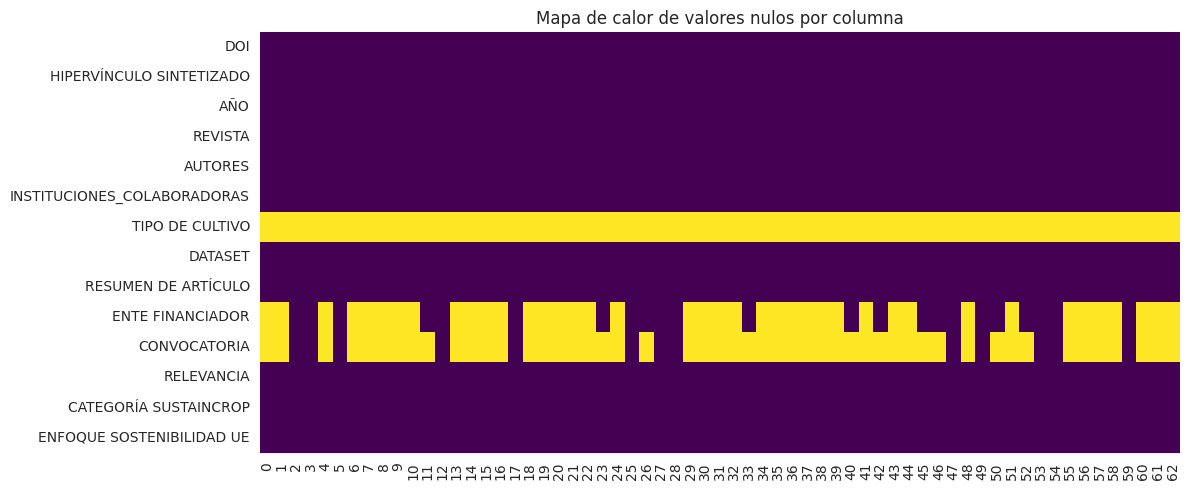

In [177]:
# Visualizar nulos
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull().T, cbar=False, cmap="viridis", yticklabels=True)
plt.title("Mapa de calor de valores nulos por columna")
plt.tight_layout()
plt.show()

### 5. Tipos de datos y conversiones

In [178]:
print("=== TIPOS DE DATOS ACTUALES ===")
display(df.dtypes)

=== TIPOS DE DATOS ACTUALES ===


,0
DOI,object
HIPERVÍNCULO SINTETIZADO,object
AÑO,int64
REVISTA,object
AUTORES,object
INSTITUCIONES_COLABORADORAS,object
TIPO DE CULTIVO,float64
DATASET,object
RESUMEN DE ARTÍCULO,object
ENTE FINANCIADOR,object


### 6. Medidas de tendencia central

In [179]:
col_num = "AÑO"

print(f"=== Medidas de Tendencia Central para '{col_num}' ===")
print(f"Media:     {df[col_num].mean():.2f}")
print(f"Mediana:   {df[col_num].median():.2f}")
print(f"Moda:      {df[col_num].mode().values}")
print(f"Desv. Est: {df[col_num].std():.2f}")
print(f"Mín:       {df[col_num].min()}")
print(f"Máx:       {df[col_num].max()}")
print(f"Rango:     {df[col_num].max() - df[col_num].min()}")

=== Medidas de Tendencia Central para 'AÑO' ===
Media:     2025.49
Mediana:   2026.00
Moda:      [2026]
Desv. Est: 1.16
Mín:       2019
Máx:       2026
Rango:     7


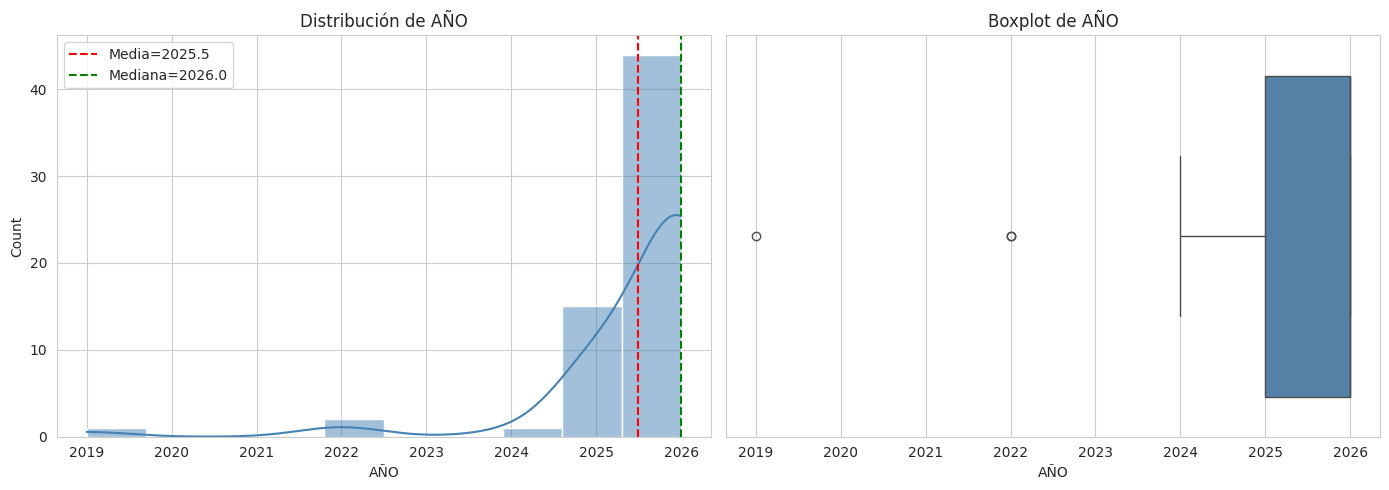

In [180]:
# Histograma + boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df[col_num], bins=10, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title(f"Distribución de {col_num}")
axes[0].axvline(df[col_num].mean(), color="red", linestyle="--", label=f"Media={df[col_num].mean():.1f}")
axes[0].axvline(df[col_num].median(), color="green", linestyle="--", label=f"Mediana={df[col_num].median():.1f}")
axes[0].legend()

sns.boxplot(x=df[col_num], ax=axes[1], color="steelblue")
axes[1].set_title(f"Boxplot de {col_num}")

plt.tight_layout()
plt.show()

### 7. Análisis de columnas categóricas

In [181]:
#Frecuencias categóricas
cols_cat = ["RELEVANCIA", "CATEGORÍA SUSTAINCROP", "DATASET"]

for col in cols_cat:
    print(f"\n=== Frecuencias de '{col}' ===")
    freq = df[col].value_counts()
    freq_pct = (df[col].value_counts(normalize=True) * 100).round(2)
    tabla = pd.DataFrame({"Cantidad": freq, "%": freq_pct})
    display(tabla)


=== Frecuencias de 'RELEVANCIA' ===


,Cantidad,%
RELEVANCIA,,
Alta,47,74.6
Media,16,25.4



=== Frecuencias de 'CATEGORÍA SUSTAINCROP' ===


,Cantidad,%
CATEGORÍA SUSTAINCROP,,
Investigación & Conocimiento,55,87.30
Industria & Mercado,3,4.76
Sector Primario,3,4.76
Sociedad Civil & Territorio,2,3.17



=== Frecuencias de 'DATASET' ===


,Cantidad,%
DATASET,,
No,36,57.14
Sí,27,42.86


/tmp/ipykernel_7267/336870843.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette=palette)


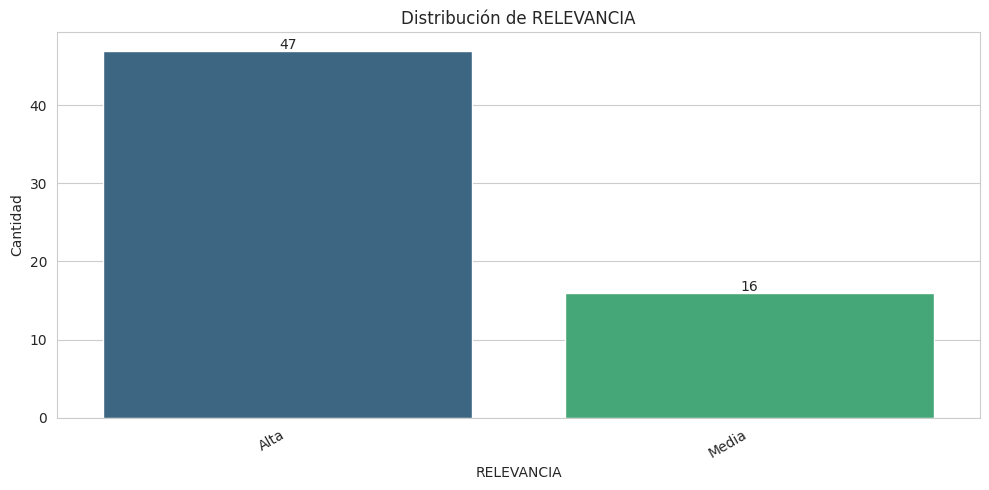

/tmp/ipykernel_7267/336870843.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette=palette)


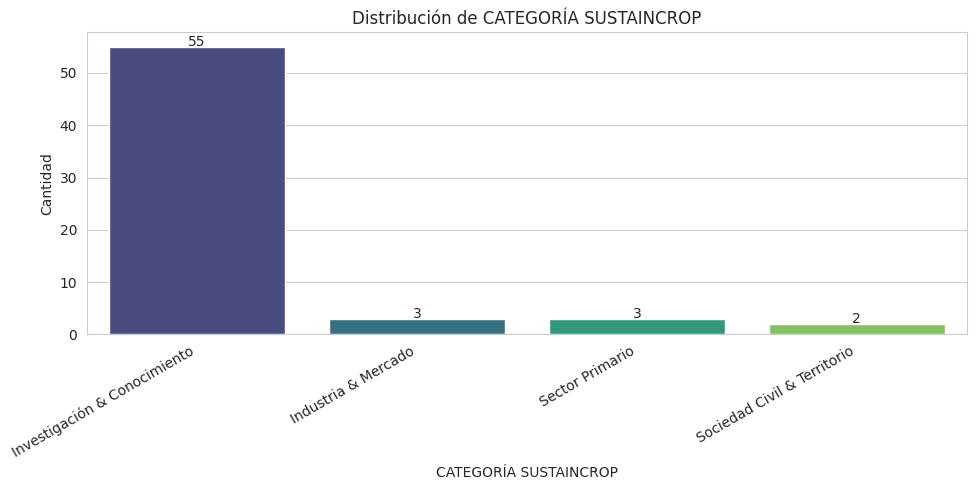

/tmp/ipykernel_7267/336870843.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette=palette)


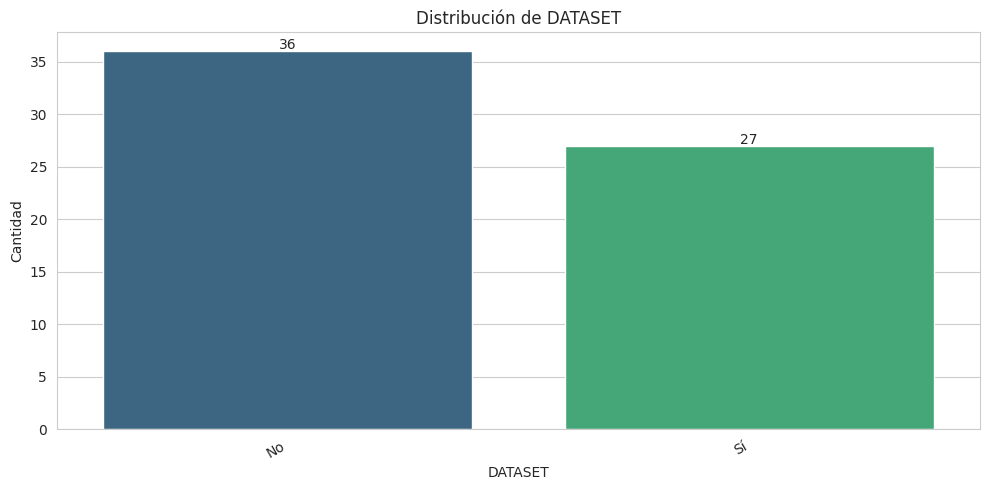

In [182]:
def bar_char(feature, data=df, figsize=(10, 5), palette="viridis"):
    """Grafica distribución de una columna categórica."""
    counts = data[feature].value_counts()
    plt.figure(figsize=figsize)
    sns.barplot(x=counts.index, y=counts.values, palette=palette)
    plt.title(f"Distribución de {feature}")
    plt.ylabel("Cantidad")
    plt.xticks(rotation=30, ha="right")
    for i, v in enumerate(counts.values):
        plt.text(i, v + 0.2, str(v), ha="center", fontsize=10)
    plt.tight_layout()
    plt.show()

for col in cols_cat:
    bar_char(col)

In [183]:
# Top 10 REVISTA
print("=== TOP 10 REVISTAS con más artículos ===")
top_revistas = df["REVISTA"].value_counts().head(10)
display(top_revistas)

=== TOP 10 REVISTAS con más artículos ===


,count
REVISTA,
Corporación Colombiana de Investigación Agropecuaria (Agrosavia) eBooks,5
Memorias Seminario Científico Cenicafé,3
Revista de la Academia Colombiana de Ciencias Exactas Físicas y Naturales,3
Avances Técnicos Cenicafé,3
Revista Cenicafé,2
Revista Colombiana de Entomología,2
Agriculture,2
Revista de Ciencias Agrícolas,2
Florida Entomologist,2


/tmp/ipykernel_7267/454954676.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_revistas.index, x=top_revistas.values, palette="viridis")


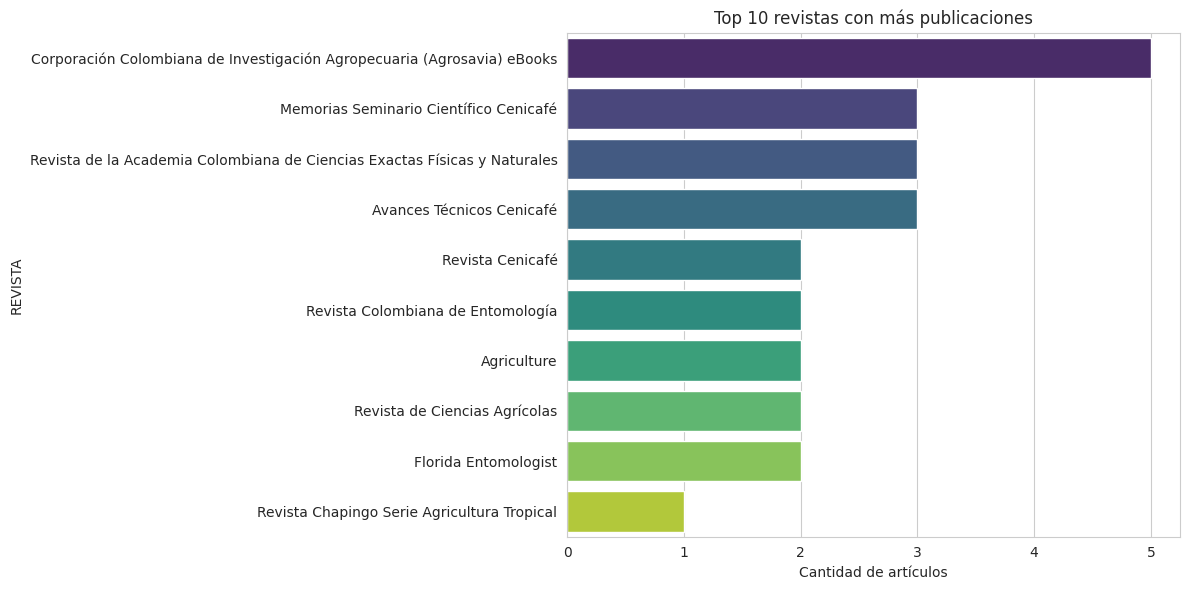

In [184]:
plt.figure(figsize=(12, 6))
sns.barplot(y=top_revistas.index, x=top_revistas.values, palette="viridis")
plt.title("Top 10 revistas con más publicaciones")
plt.xlabel("Cantidad de artículos")
plt.tight_layout()
plt.show()

In [185]:
# Cruce RELEVANCIA vs CATEGORÍA
cruz = pd.crosstab(df["CATEGORÍA SUSTAINCROP"], df["RELEVANCIA"])
print("=== Cruce CATEGORÍA SUSTAINCROP vs RELEVANCIA ===")
display(cruz)

=== Cruce CATEGORÍA SUSTAINCROP vs RELEVANCIA ===


RELEVANCIA,Alta,Media
CATEGORÍA SUSTAINCROP,,
Industria & Mercado,2,1
Investigación & Conocimiento,42,13
Sector Primario,3,0
Sociedad Civil & Territorio,0,2


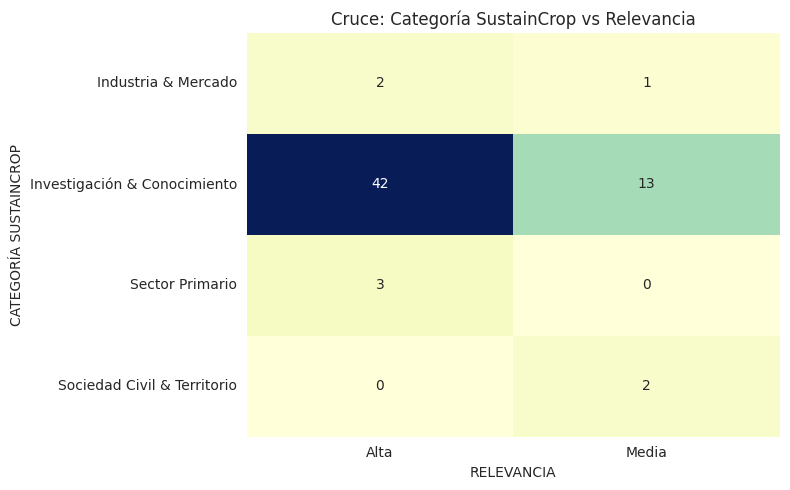

In [186]:
plt.figure(figsize=(8, 5))
sns.heatmap(cruz, annot=True, fmt="d", cmap="YlGnBu", cbar=False)
plt.title("Cruce: Categoría SustainCrop vs Relevancia")
plt.tight_layout()
plt.show()

### 8. Distribuciones y visualizaciones adicionales

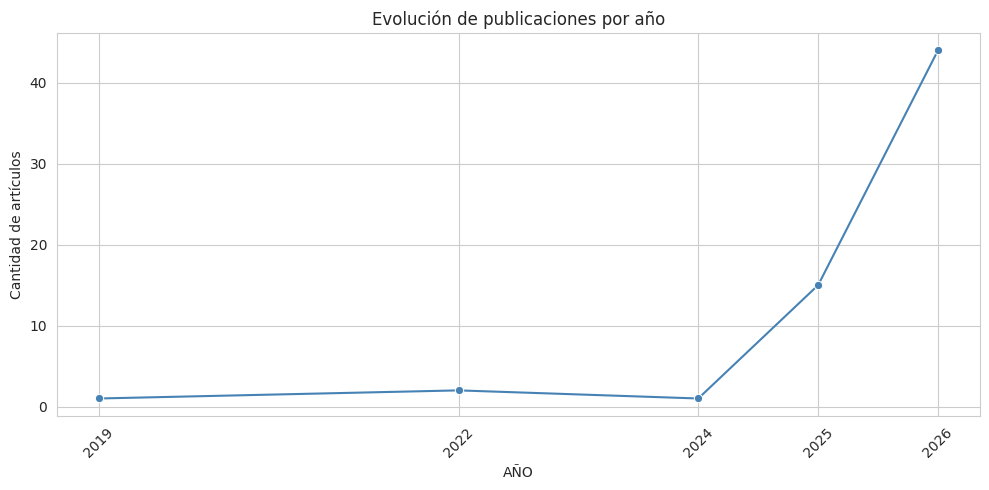

In [187]:
#Evolución temporal
evolucion = df.groupby("AÑO").size().reset_index(name="cantidad")
plt.figure(figsize=(10, 5))
sns.lineplot(data=evolucion, x="AÑO", y="cantidad", marker="o", color="steelblue")
plt.title("Evolución de publicaciones por año")
plt.ylabel("Cantidad de artículos")
plt.xticks(evolucion["AÑO"], rotation=45)
plt.tight_layout()
plt.show()

In [188]:
#Top autores
# Separar autores (vienen separados por ";")
autores = df["AUTORES"].str.split(";").explode().str.strip()
top_autores = autores.value_counts().head(10)
print("=== TOP 10 AUTORES más frecuentes ===")
display(top_autores)

=== TOP 10 AUTORES más frecuentes ===


,count
AUTORES,
Pablo Benavides,6
Eduardo Duque‐Dussán,5
Germán Vargas,4
Zulma Gil-Palacio,4
Juan Rodrigo Sanz-Uribe,3
Darío Antonio Vallejo Timarán,2
Luis Alberto Mendoza Vargas,2
Marisol Giraldo-Jaramillo,2
Paula A. Figueroa‐Varela,2


/tmp/ipykernel_7267/3368203031.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_autores.index, x=top_autores.values, palette="viridis")


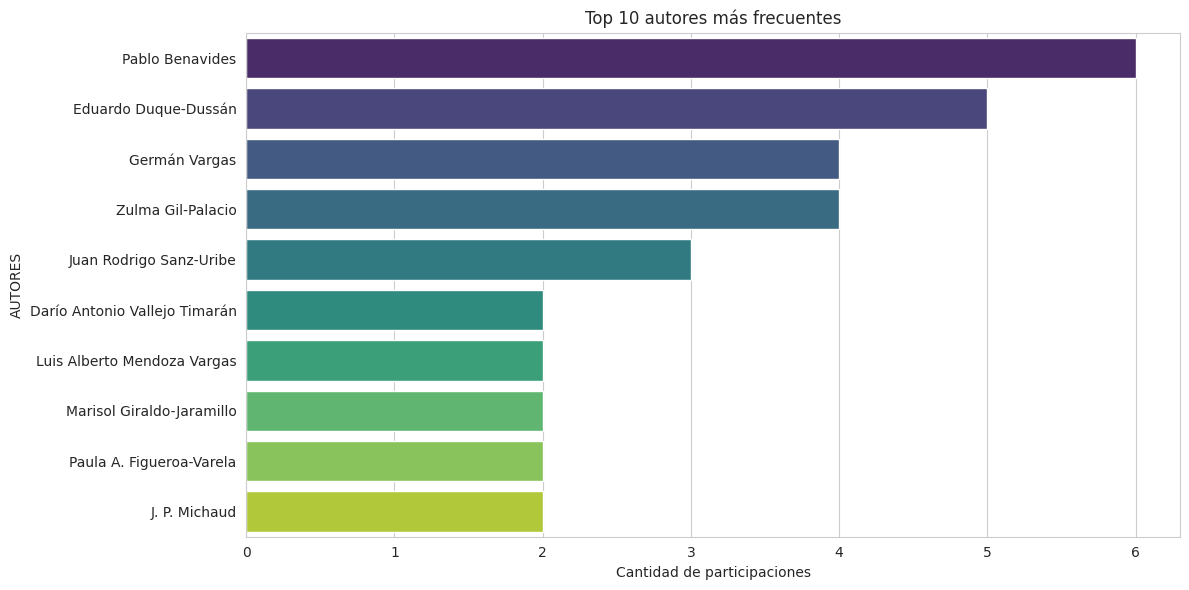

In [189]:
plt.figure(figsize=(12, 6))
sns.barplot(y=top_autores.index, x=top_autores.values, palette="viridis")
plt.title("Top 10 autores más frecuentes")
plt.xlabel("Cantidad de participaciones")
plt.tight_layout()
plt.show()

### 9. Transform Vector / Feature Engineering

| Feature | Origen | Tipo |
|:---|:---|:---|
| **PERIODO** | `AÑO` | Categórica (binning con `pd.cut`) |
| **N_AUTORES** | `AUTORES` | Numérica (conteo) |

### 9.1 Binning de AÑO por períodos

In [190]:
bins = [2019, 2022, 2024, 2026, 2027]   # el último es 2027, no lo toma en cuenta por el right=False
labels = ["2020-2021", "2022-2023", "2024-2025", "2026"]

df["PERIODO"] = pd.cut(df["AÑO"], bins=bins, labels=labels, right=False)

print("=== Distribución por PERIODO ===")
display(df["PERIODO"].value_counts().sort_index())

=== Distribución por PERIODO ===


,count
PERIODO,
2020-2021,1
2022-2023,2
2024-2025,16
2026,44


### 9.2 Feature N_AUTORES

In [191]:
df["N_AUTORES"] = df["AUTORES"].str.count(";") + 1

print("\n=== Estadísticas de N_AUTORES ===")
print(f"Media:   {df['N_AUTORES'].mean():.1f}")
print(f"Mediana: {df['N_AUTORES'].median():.0f}")
print(f"Mín: {df['N_AUTORES'].min()}")
print(f"Máx: {df['N_AUTORES'].max()}")



=== Estadísticas de N_AUTORES ===
Media:   4.5
Mediana: 4
Mín: 1
Máx: 14


### 9.3 Visualización

/tmp/ipykernel_7267/4110139486.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


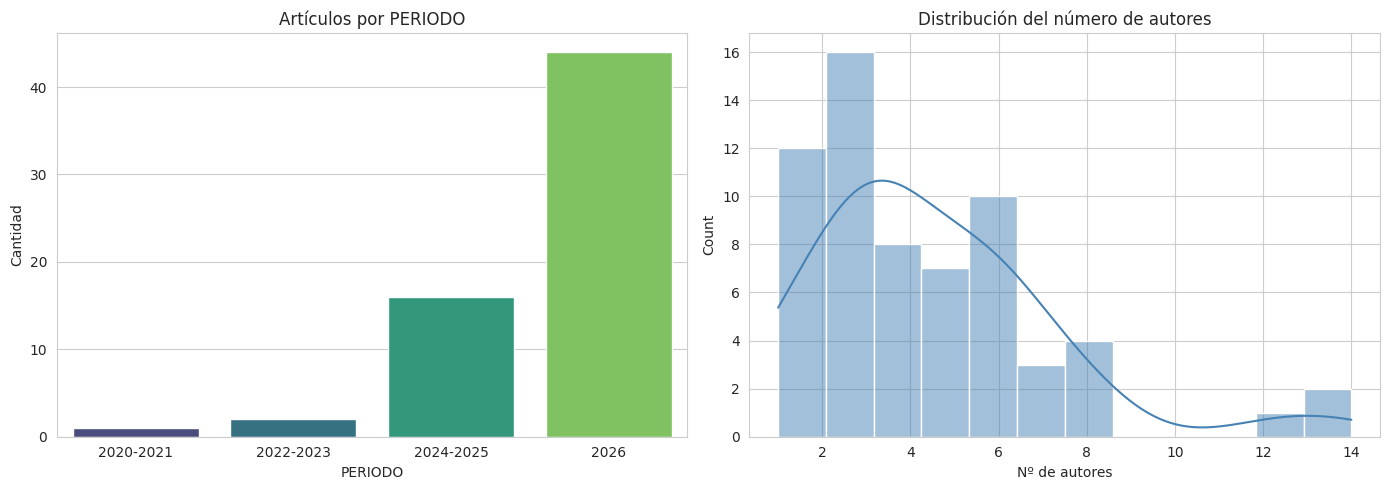

In [192]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    x=df["PERIODO"].value_counts().index,
    y=df["PERIODO"].value_counts().values,
    ax=axes[0], palette="viridis"
)
axes[0].set_title("Artículos por PERIODO")
axes[0].set_ylabel("Cantidad")

sns.histplot(df["N_AUTORES"], bins=12, ax=axes[1], color="steelblue", kde=True)
axes[1].set_title("Distribución del número de autores")
axes[1].set_xlabel("Nº de autores")

plt.tight_layout()
plt.show()

### 10. Limpieza del dataset (`df_clean`)

> El dataframe original **`df` nunca se modifica**. Todas las transformaciones se hacen sobre **`df_clean`**.

#### Criterios de limpieza

| Acción | Justificación |
|:---|:---|
| Eliminar `TIPO DE CULTIVO` | 100% de valores nulos — no aporta información |
| Eliminar `HIPERVÍNCULO SINTETIZADO` | Redundante con `DOI` (mismos 63 únicos, misma naturaleza de enlace) |
| Eliminar `ENTE FINANCIADOR` | 63% de nulos; además son cadenas muy heterogéneas donde imputar la moda carece de sentido |
| Eliminar `CONVOCATORIA` | 79% de nulos; son códigos técnicos (DOIs, referencias) sin utilidad para el análisis |
| Eliminar filas duplicadas (si existen) | Garantizar unicidad por DOI |

In [193]:
df_clean = df.copy()

In [194]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   DOI                          63 non-null     object  
 1   HIPERVÍNCULO SINTETIZADO     63 non-null     object  
 2   AÑO                          63 non-null     int64   
 3   REVISTA                      63 non-null     object  
 4   AUTORES                      63 non-null     object  
 5   INSTITUCIONES_COLABORADORAS  63 non-null     object  
 6   TIPO DE CULTIVO              0 non-null      float64 
 7   DATASET                      63 non-null     object  
 8   RESUMEN DE ARTÍCULO          63 non-null     object  
 9   ENTE FINANCIADOR             23 non-null     object  
 10  CONVOCATORIA                 13 non-null     object  
 11  RELEVANCIA                   63 non-null     object  
 12  CATEGORÍA SUSTAINCROP        63 non-null     object  
 13  ENFOQUE

In [195]:
# 1. Eliminar columnas 100% nulas o redundantes
cols_eliminar = [
    "TIPO DE CULTIVO",           # 100% nulos
    "HIPERVÍNCULO SINTETIZADO",  # redundante con DOI
    "ENTE FINANCIADOR",          # 63% nulos, cadenas heterogéneas
    "CONVOCATORIA"                # 79% nulos, códigos técnicos
]
df_clean.drop(columns=[c for c in cols_eliminar if c in df_clean.columns], inplace=True)
print(f"\nTras eliminar columnas sin valor: {df_clean.shape}")


Tras eliminar columnas sin valor: (63, 12)


In [196]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   DOI                          63 non-null     object  
 1   AÑO                          63 non-null     int64   
 2   REVISTA                      63 non-null     object  
 3   AUTORES                      63 non-null     object  
 4   INSTITUCIONES_COLABORADORAS  63 non-null     object  
 5   DATASET                      63 non-null     object  
 6   RESUMEN DE ARTÍCULO          63 non-null     object  
 7   RELEVANCIA                   63 non-null     object  
 8   CATEGORÍA SUSTAINCROP        63 non-null     object  
 9   ENFOQUE SOSTENIBILIDAD UE    63 non-null     object  
 10  PERIODO                      63 non-null     category
 11  N_AUTORES                    63 non-null     int64   
dtypes: category(1), int64(2), object(9)
memory usage: 5.8+ KB


### 11. Resumen general y conclusiones

In [197]:
print("=" * 60)
print("       RESUMEN GENERAL — DATASET SUSTAINCROP")
print("=" * 60)

print(f"\nRegistros originales:    {len(df)}")
print(f"Registros tras limpieza: {len(df_clean)}")
print(f"Columnas originales:     {df.shape[1]}")
print(f"Columnas tras limpieza:  {df_clean.shape[1]}")

print(f"\nRango de años: {df['AÑO'].min()} — {df['AÑO'].max()}")
print(f"Año con más publicaciones: {df['AÑO'].value_counts().idxmax()} ({df['AÑO'].value_counts().max()} artículos)")

print(f"\nRevista más frecuente: {df['REVISTA'].value_counts().idxmax()} ({df['REVISTA'].value_counts().max()} artículos)")
print(f"Total de revistas distintas: {df['REVISTA'].nunique()}")

print(f"\nRelevancia Alta: {(df['RELEVANCIA']=='Alta').sum()} artículos ({(df['RELEVANCIA']=='Alta').mean()*100:.1f}%)")

print(f"\nCategorías SustainCrop:")
for cat, cant in df["CATEGORÍA SUSTAINCROP"].value_counts().items():
    print(f"   - {cat}: {cant} ({cant/len(df)*100:.1f}%)")

print(f"\nArtículos que aportan dataset: {(df['DATASET']=='Sí').sum()}")

print(f"\nFeature Engineering (Transform Vector):")
print(f"   - PERIODO: {df['PERIODO'].nunique()} períodos creados por binning de AÑO")
print(f"   - N_AUTORES: media {df['N_AUTORES'].mean():.1f} | máx {df['N_AUTORES'].max()}")

print(f"\nLimpieza aplicada:")
print("   - Columnas eliminadas: TIPO DE CULTIVO, HIPERVÍNCULO SINTETIZADO, ENTE FINANCIADOR, CONVOCATORIA")
print("   - Justificación: nulos excesivos (>60%) o redundancia")

       RESUMEN GENERAL — DATASET SUSTAINCROP

Registros originales:    63
Registros tras limpieza: 63
Columnas originales:     16
Columnas tras limpieza:  12

Rango de años: 2019 — 2026
Año con más publicaciones: 2026 (44 artículos)

Revista más frecuente: Corporación Colombiana de Investigación Agropecuaria (Agrosavia) eBooks (5 artículos)
Total de revistas distintas: 48

Relevancia Alta: 47 artículos (74.6%)

Categorías SustainCrop:
   - Investigación & Conocimiento: 55 (87.3%)
   - Industria & Mercado: 3 (4.8%)
   - Sector Primario: 3 (4.8%)
   - Sociedad Civil & Territorio: 2 (3.2%)

Artículos que aportan dataset: 27

Feature Engineering (Transform Vector):
   - PERIODO: 4 períodos creados por binning de AÑO
   - N_AUTORES: media 4.5 | máx 14

Limpieza aplicada:
   - Columnas eliminadas: TIPO DE CULTIVO, HIPERVÍNCULO SINTETIZADO, ENTE FINANCIADOR, CONVOCATORIA
   - Justificación: nulos excesivos (>60%) o redundancia
